# RQ1 - When states cut support, do students pay more?

**Question.** Within the same public four-year institution, does a fall in
state appropriations per student show up as higher net tuition revenue per
student?

**Design.** Institution and year fixed effects, so we compare an institution
to *itself* in other years and net out anything common to all institutions in
a given year. Standard errors clustered by institution.

**Sample.** Public four-year (sector 1), 2004-2017 - the years `finance` exists.

**A caveat worth stating out loud.** IPEDS has no per-student net price in
these tables. We use net tuition & fee revenue per FTE, the standard
institution-level proxy. It is a revenue measure, not a price sticker.

In [1]:
import sys; sys.path.insert(0, "..")
import matplotlib.pyplot as plt
import pandas as pd
from src import panels
from src.regression import panel_ols
pd.set_option("display.width", 120)

In [2]:
p = panels.rq1()
print(f"{len(p):,} institution-years, {p.unitid.nunique():,} institutions, {p.year.min()}-{p.year.max()}")
p[["net_tuition_per_fte_real", "appropriations_per_fte_real", "fte", "pct_pell"]].describe().round(1)

8,820 institution-years, 731 institutions, 2004-2017


,net_tuition_per_fte_real,appropriations_per_fte_real,fte,pct_pell
count,8820.0,8820.0,8820.0,6346.0
mean,7224.0,10735.4,10479.8,0.4
std,4739.1,26492.6,10324.4,0.1
min,253.8,15.4,112.0,0.0
25%,4469.2,4824.5,3050.0,0.3
50%,6167.3,6660.9,6830.5,0.4
75%,8783.9,9548.2,14144.2,0.4
max,46411.5,1630818.8,69248.0,1.0


Both sides go into the model in logs, so the coefficient is an elasticity.

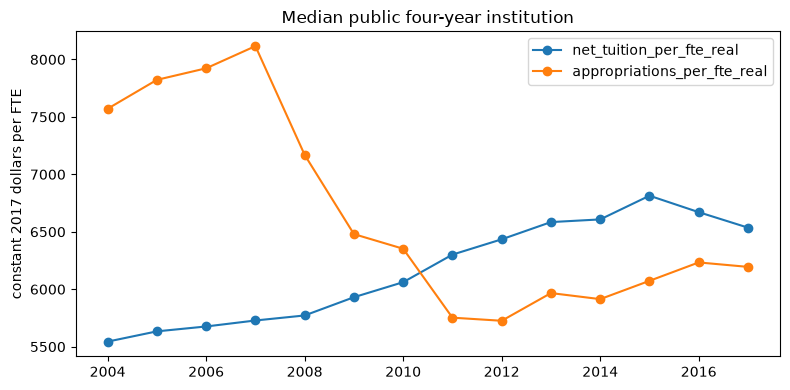

In [3]:
ax = (p.groupby("year")[["net_tuition_per_fte_real", "appropriations_per_fte_real"]]
        .median().plot(figsize=(8, 4), marker="o"))
ax.set(ylabel="constant 2017 dollars per FTE", xlabel="",
       title="Median public four-year institution")
plt.tight_layout(); plt.show()

In [4]:
res = panel_ols(p, "log_net_tuition_per_fte", ["log_appr_per_fte", "log_fte"], name="RQ1")
print(res.summary())

RQ1: 8,820 obs, 731 institutions, within R2=-0.005
                    coef  stderr   tstat  pvalue  ci_low  ci_high
log_appr_per_fte -0.0674  0.0215 -3.1372  0.0017 -0.1094  -0.0253
log_fte          -0.3738  0.0480 -7.7866  0.0000 -0.4679  -0.2797


**Reading the coefficient.** `log_appr_per_fte` is the elasticity of net
tuition revenue per student with respect to state support per student. A
negative value means that when state money falls, tuition revenue rises -
students absorb part of the cut.

Multiply by 10 for the effect of a 10% cut.

In [5]:
b = res.coefs.loc["log_appr_per_fte"]
print(f"A 10% cut in state support per student is associated with a "
      f"{-b.coef * 10:+.2f}% change in net tuition revenue per student "
      f"(95% CI {-b.ci_high * 10:+.2f} to {-b.ci_low * 10:+.2f}).")

A 10% cut in state support per student is associated with a +0.67% change in net tuition revenue per student (95% CI +0.25 to +1.09).


## Export for Stata

In [6]:
for f in panels.save(p, "rq1_panel"):
    print(f)
# In Stata:  use "results/rq1_panel.dta", clear
#            xtset unitid year
#            xtreg log_net_tuition_per_fte log_appr_per_fte log_fte i.year, fe vce(cluster unitid)

results/rq1_panel.parquet
results/rq1_panel.csv
results/rq1_panel.dta
